### ДЗ 1: обнаружение аномалий

In [15]:
# импорт необходимых библиотек

import random
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [16]:
# загрузка данных

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample_submission = pd.read_csv("sample_submission.csv")

print(f"\nTrain: {train.shape}")
print(f"Test: {test.shape}")
print(f"Sample_submission: {sample_submission.shape}")

display(train.head())
display(test.head())
display(sample_submission.head())


Train: (7828, 8)
Test: (3355, 7)
Sample_submission: (3355, 2)


,id,sensor_0,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,anomaly
0,107321,0.747920,0.119917,0.224249,0.284513,0.474236,0.153085,0
1,109814,1.842037,-0.322747,0.515324,-1.919162,-0.639667,-0.527665,0
2,103587,-1.249928,0.176276,-0.997425,0.544363,-0.242429,0.214614,0
3,107049,-1.249928,0.176276,-0.997425,0.544363,-0.242429,0.214614,0
4,107567,-1.249928,0.176276,-0.997425,0.544363,-0.242429,0.214614,0


,id,sensor_0,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5
0,109042,-1.070922,-0.128883,0.009373,0.041152,-0.850912,0.088048
1,103298,-1.107698,0.201516,0.115089,0.491647,-0.674876,0.082374
2,106193,-1.151572,0.171901,-0.220874,0.570873,-0.530173,0.110601
3,106520,-1.249928,0.176276,-0.997425,0.544363,-0.242429,0.214614
4,105007,1.111388,-0.292402,0.448689,-0.073995,0.333835,-0.175686


,id,anomaly_score
0,109042,0.0
1,103298,0.0
2,106193,0.0
3,106520,0.0
4,105007,0.0


In [17]:
# анализ классов (они есть только в train)

class_counts = train["anomaly"].value_counts().sort_index()
class_share = train["anomaly"].value_counts(normalize=True).sort_index()

summary = pd.DataFrame({
    "count": class_counts,
    "share": class_share
})
summary.index = ["normal (0)", "fraud (1)"]

display(summary)

,count,share
normal (0),7646,0.97675
fraud (1),182,0.02325


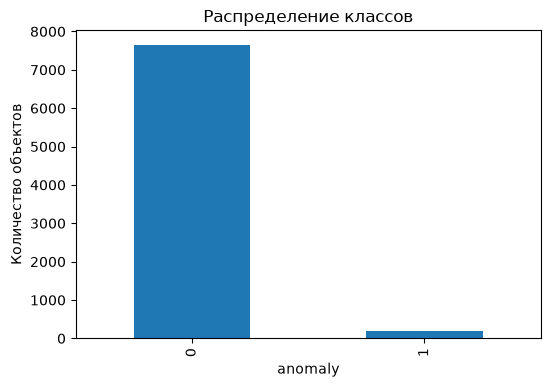

Доля fraud: 2.3250%
Доля normal: 97.6750%


In [18]:
fig, ax = plt.subplots(figsize=(6, 4))
class_counts.plot(kind="bar", ax=ax)
ax.set_title("Распределение классов")
ax.set_xlabel("anomaly")
ax.set_ylabel("Количество объектов")
plt.show()

fraud_rate = train["anomaly"].mean()
print(f"Доля fraud: {fraud_rate:.4%}")
print(f"Доля normal: {1 - fraud_rate:.4%}")

В выборке, как и в учебном ноутбуке, виден дисбаланс классов. Это необходимо учитывать при обучении модели. 
Для оценки качества будем использовать метрику Average Precision. 
При обучении персептрона рассмотрим взвешенную функцию потерь для компенсации дисбаланса классов.

In [19]:
# разбиение выборки на обучающую и валидационную

X = train.drop(columns=["id", "anomaly"])  # они не являются признаками
y = train["anomaly"].astype(np.int64)

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y,
)

print("Train:", X_train.shape, y_train.shape)
print("Val:", X_val.shape, y_val.shape)

Train: (6262, 6) (6262,)
Val: (1566, 6) (1566,)


In [20]:
# масштабирование признаков

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)

y_train_np = y_train.to_numpy().astype(np.float32)
y_val_np = y_val.to_numpy().astype(np.float32)

In [21]:
X_test = test.drop(columns="id")
X_test_scaled = scaler.transform(X_test).astype(np.float32)

In [22]:
print(X_train_scaled.shape, X_val_scaled.shape, X_test_scaled.shape)

(6262, 6) (1566, 6) (3355, 6)


In [23]:
# разбиваем на мини-батчи для обучения

BATCH_SIZE = 256

train_ds = TensorDataset(
    torch.tensor(X_train_scaled),
    torch.tensor(y_train_np),
)
val_ds = TensorDataset(
    torch.tensor(X_val_scaled),
    torch.tensor(y_val_np),
)
test_ds = TensorDataset(
    torch.tensor(X_test_scaled),
)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)

val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

In [24]:
# многослойный персептрон

class MLP(nn.Module):
    def __init__(
        self,
        input_dim,
        hidden_dims=(64, 32),
        dropout=0.0,
        use_batchnorm=False,
    ):
        super().__init__()

        layers = []
        prev_dim = input_dim

        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, hidden_dim))

            if use_batchnorm:
                layers.append(nn.BatchNorm1d(hidden_dim))

            layers.append(nn.SiLU())

            if dropout > 0:
                layers.append(nn.Dropout(dropout))

            prev_dim = hidden_dim

        layers.append(nn.Linear(prev_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)


# создание базовой модели
input_dim = X_train_scaled.shape[1]

baseline_mlp = MLP(
    input_dim=input_dim,
    hidden_dims=(64, 32),
    dropout=0.0,
    use_batchnorm=False,
).to(device)

baseline_mlp

MLP(
  (net): Sequential(
    (0): Linear(in_features=6, out_features=64, bias=True)
    (1): SiLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): SiLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)

In [25]:
# используем функцию потерь BCEWithLogitsLoss для обучения модели

n_pos = y_train.sum()
n_neg = len(y_train) - n_pos

pos_weight_value = n_neg / n_pos
pos_weight = torch.tensor([pos_weight_value], dtype=torch.float32, device=device)

print("pos_weight:", float(pos_weight_value))  # вес ошибки на положительных примерах 
                                               # в 41 раз больше, чем на отрицательных

pos_weight: 41.89041095890411


In [26]:
# функция обучения
# изменена относительно обучающего ноутбука для удобства обучения на полной выборке

def train_classifier(
    model,
    train_loader,
    val_loader=None,
    epochs=20,
    lr=1e-3,
    weight_decay=0.0,
    patience=4,
):
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay,
    )

    history = {"train_loss": [], "val_loss": [], "val_ap": []}
    best_val_ap = -float("inf")
    best_state = copy.deepcopy(model.state_dict())
    bad_epochs = 0

    for epoch in range(1, epochs + 1):
        model.train()
        train_losses = []

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item() * len(xb))

        # обучение без валидационной выборки
        # (для обучения итоговой модели после подбора гиперпараметров)
        if val_loader is None:
            train_loss = np.sum(train_losses) / len(train_loader.dataset)
            history["train_loss"].append(train_loss)
            print(
                f"Epoch {epoch:02d} | "
                f"train_loss={train_loss:.5f}"
            )
            continue

        model.eval()
        val_losses = []
        val_scores, val_targets = [], []

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device)
                yb = yb.to(device)

                logits = model(xb)
                loss = criterion(logits, yb)
                val_losses.append(loss.item() * len(xb))
                val_scores.append(torch.sigmoid(logits).cpu().numpy())
                val_targets.append(yb.cpu().numpy())

        train_loss = np.sum(train_losses) / len(train_loader.dataset)
        val_loss = np.sum(val_losses) / len(val_loader.dataset)
        val_ap = average_precision_score(np.concatenate(val_targets), np.concatenate(val_scores))

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_ap"].append(val_ap)

        print(
            f"Epoch {epoch:02d} | "
            f"train_loss={train_loss:.5f} | "
            f"val_loss={val_loss:.5f} | val_AP={val_ap:.5f}"
        )

        if val_ap > best_val_ap:
            best_val_ap = val_ap
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1

        if bad_epochs >= patience:
            print("Early stopping")
            break

    if val_loader is not None:
        model.load_state_dict(best_state)
    return history


# функция получения предсказания

def predict_classifier(model, loader):
    model.eval()

    all_probs = []
    all_targets = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)

            logits = model(xb)
            probs = torch.sigmoid(logits)

            all_probs.append(probs.cpu().numpy())
            all_targets.append(yb.numpy())

    return np.concatenate(all_targets), np.concatenate(all_probs)

На этом исследование данных закончено. Осталось только подобрать гиперпараметры модели.

In [27]:
from itertools import product

# перебор гиперпараметров

hidden_dims_values = [
    (64, 32),
    (128, 64),
    (64, 32, 16),
    (128, 64, 32),
]

lr_values = [5e-4, 1e-3, 2e-3]
dropout_values = [0.0, 0.1]
batchnorm_values = [False, True]
weight_decay_values = [0.0, 1e-4]

experiments = {}

for hidden_dims, lr, dropout, batchnorm, weight_decay in product(
    hidden_dims_values,
    lr_values,
    dropout_values,
    batchnorm_values,
    weight_decay_values
):
    name = f"{hidden_dims}_lr{lr}_bn{int(batchnorm)}_dp{dropout}_wd{weight_decay}"

    experiments[name] = {
        "hidden_dims": hidden_dims,
        "lr": lr,
        "dropout": dropout,
        "batchnorm": batchnorm,
        "weight_decay": weight_decay,
    }

In [28]:
classifier_results = []
trained_classifiers = {}

for name, cfg in experiments.items():
    print("\n" + "=" * 70)
    print("Experiment:", name)

    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    model = MLP(
        input_dim=input_dim,
        hidden_dims=cfg["hidden_dims"],
        dropout=cfg["dropout"],
        use_batchnorm=cfg["batchnorm"],
    ).to(device)

    history = train_classifier(
        model,
        train_loader,
        val_loader,
        epochs=160,
        lr=cfg["lr"],
        weight_decay=cfg["weight_decay"],
        patience=10,
    )

    y_true_tmp, scores_tmp = predict_classifier(model, val_loader)

    ap = average_precision_score(y_true_tmp, scores_tmp)

    classifier_results.append({
        "model": name,
        "AP": ap,
    })

    trained_classifiers[name] = model

classifier_results_df = (
    pd.DataFrame(classifier_results)
    .sort_values("AP", ascending=False)
    .reset_index(drop=True)
)

display(classifier_results_df)


Experiment: (64, 32)_lr0.0005_bn0_dp0.0_wd0.0
Epoch 01 | train_loss=1.26680 | val_loss=1.19851 | val_AP=0.32892
Epoch 02 | train_loss=1.10142 | val_loss=1.08627 | val_AP=0.40021
Epoch 03 | train_loss=1.00340 | val_loss=1.00438 | val_AP=0.41377
Epoch 04 | train_loss=0.93291 | val_loss=0.94711 | val_AP=0.41824
Epoch 05 | train_loss=0.88068 | val_loss=0.90007 | val_AP=0.42477
Epoch 06 | train_loss=0.83576 | val_loss=0.85813 | val_AP=0.43037
Epoch 07 | train_loss=0.79556 | val_loss=0.82324 | val_AP=0.43923
Epoch 08 | train_loss=0.76151 | val_loss=0.79310 | val_AP=0.44581
Epoch 09 | train_loss=0.73277 | val_loss=0.76935 | val_AP=0.45888
Epoch 10 | train_loss=0.70998 | val_loss=0.74997 | val_AP=0.46282
Epoch 11 | train_loss=0.69494 | val_loss=0.73421 | val_AP=0.47821
Epoch 12 | train_loss=0.68316 | val_loss=0.72518 | val_AP=0.48808
Epoch 13 | train_loss=0.67554 | val_loss=0.71291 | val_AP=0.49618
Epoch 14 | train_loss=0.66729 | val_loss=0.70588 | val_AP=0.50048
Epoch 15 | train_loss=0.66122

,model,AP
0,"(128, 64, 32)_lr0.002_bn0_dp0.0_wd0.0001",0.765510
1,"(128, 64, 32)_lr0.002_bn0_dp0.0_wd0.0",0.765500
2,"(64, 32, 16)_lr0.001_bn0_dp0.1_wd0.0",0.738604
3,"(128, 64)_lr0.001_bn1_dp0.0_wd0.0",0.736230
4,"(128, 64)_lr0.001_bn1_dp0.0_wd0.0001",0.736146
...,...,...
91,"(64, 32)_lr0.0005_bn0_dp0.1_wd0.0001",0.613579
92,"(64, 32)_lr0.0005_bn0_dp0.0_wd0.0",0.612992
93,"(64, 32)_lr0.0005_bn0_dp0.0_wd0.0001",0.612987
94,"(64, 32)_lr0.002_bn1_dp0.0_wd0.0001",0.611414


In [29]:
# лучшие гиперпараметры

best_name = classifier_results_df.iloc[0]["model"]
best_cfg = experiments[best_name]

print("Validation AP:", classifier_results_df.iloc[0]["AP"])
print("Best parameters:", best_cfg)


Validation AP: 0.765510266456983
Best parameters: {'hidden_dims': (128, 64, 32), 'lr': 0.002, 'dropout': 0.0, 'batchnorm': False, 'weight_decay': 0.0001}


In [44]:
# обучение базовой модели

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

baseline_mlp = MLP(
    input_dim=input_dim,
    hidden_dims=best_cfg["hidden_dims"],
    dropout=best_cfg["dropout"],
    use_batchnorm=best_cfg["batchnorm"],
).to(device)

history_baseline = train_classifier(
    baseline_mlp,
    train_loader,
    val_loader,
    epochs=160,
    lr=best_cfg["lr"],
    weight_decay=best_cfg["weight_decay"],
    patience=10,
)

Epoch 01 | train_loss=1.01016 | val_loss=0.80307 | val_AP=0.45728
Epoch 02 | train_loss=0.74091 | val_loss=0.69035 | val_AP=0.51876
Epoch 03 | train_loss=0.67076 | val_loss=0.66594 | val_AP=0.52925
Epoch 04 | train_loss=0.63962 | val_loss=0.62934 | val_AP=0.56044
Epoch 05 | train_loss=0.61786 | val_loss=0.61744 | val_AP=0.56346
Epoch 06 | train_loss=0.59167 | val_loss=0.60658 | val_AP=0.54808
Epoch 07 | train_loss=0.58869 | val_loss=0.56671 | val_AP=0.59112
Epoch 08 | train_loss=0.56041 | val_loss=0.55064 | val_AP=0.60567
Epoch 09 | train_loss=0.54158 | val_loss=0.54318 | val_AP=0.60832
Epoch 10 | train_loss=0.53252 | val_loss=0.53375 | val_AP=0.61655
Epoch 11 | train_loss=0.53294 | val_loss=0.52748 | val_AP=0.62410
Epoch 12 | train_loss=0.51989 | val_loss=0.56365 | val_AP=0.62420
Epoch 13 | train_loss=0.51421 | val_loss=0.54341 | val_AP=0.60862
Epoch 14 | train_loss=0.53741 | val_loss=0.53188 | val_AP=0.59329
Epoch 15 | train_loss=0.51383 | val_loss=0.51621 | val_AP=0.60454
Epoch 16 |

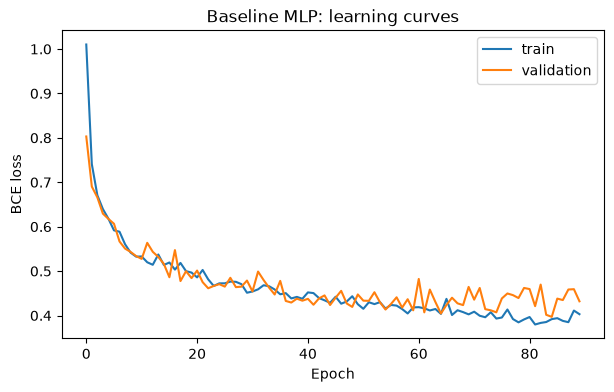

In [45]:
plt.figure(figsize=(7, 4))
plt.plot(history_baseline["train_loss"], label="train")
plt.plot(history_baseline["val_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("BCE loss")
plt.title("Baseline MLP: learning curves")
plt.legend()
plt.show()

In [46]:
# оценка модели

y_val_true, val_probs = predict_classifier(baseline_mlp, val_loader)
print("Average Precision:", average_precision_score(y_val_true, val_probs))

Average Precision: 0.7653110659057505


In [47]:
# подготовка данных для итогового обучения

final_scaler = StandardScaler()

X_full_scaled = final_scaler.fit_transform(X).astype(np.float32)
X_test_final_scaled = final_scaler.transform(X_test).astype(np.float32)

y_full_np = y.to_numpy().astype(np.float32)

full_ds = TensorDataset(
    torch.tensor(X_full_scaled),
    torch.tensor(y_full_np),
)

full_loader = DataLoader(
    full_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
)

test_ds = TensorDataset(
    torch.tensor(X_test_final_scaled),
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

In [48]:
# вес класса по всей обучающей выборке

n_pos = y.sum()
n_neg = len(y) - n_pos

pos_weight_value = n_neg / n_pos
pos_weight = torch.tensor([pos_weight_value], dtype=torch.float32, device=device)

print("pos_weight:", float(pos_weight_value))

pos_weight: 42.010989010989015


In [49]:
# обучение итоговой модели

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

final_model = MLP(
    input_dim=X_full_scaled.shape[1],
    hidden_dims=best_cfg["hidden_dims"],
    dropout=best_cfg["dropout"],
    use_batchnorm=best_cfg["batchnorm"],
).to(device)

history = train_classifier(
    final_model,
    full_loader,
    val_loader=None,
    epochs=160,
    lr=best_cfg["lr"],
    weight_decay=best_cfg["weight_decay"],
)

Epoch 01 | train_loss=0.96083
Epoch 02 | train_loss=0.69089
Epoch 03 | train_loss=0.64767
Epoch 04 | train_loss=0.61816
Epoch 05 | train_loss=0.58580
Epoch 06 | train_loss=0.57607
Epoch 07 | train_loss=0.56512
Epoch 08 | train_loss=0.54908
Epoch 09 | train_loss=0.53433
Epoch 10 | train_loss=0.52188
Epoch 11 | train_loss=0.55277
Epoch 12 | train_loss=0.51110
Epoch 13 | train_loss=0.50145
Epoch 14 | train_loss=0.52542
Epoch 15 | train_loss=0.51294
Epoch 16 | train_loss=0.49114
Epoch 17 | train_loss=0.50253
Epoch 18 | train_loss=0.48878
Epoch 19 | train_loss=0.48634
Epoch 20 | train_loss=0.49954
Epoch 21 | train_loss=0.46790
Epoch 22 | train_loss=0.47451
Epoch 23 | train_loss=0.45671
Epoch 24 | train_loss=0.46319
Epoch 25 | train_loss=0.46940
Epoch 26 | train_loss=0.47058
Epoch 27 | train_loss=0.44442
Epoch 28 | train_loss=0.43874
Epoch 29 | train_loss=0.44386
Epoch 30 | train_loss=0.45032
Epoch 31 | train_loss=0.43502
Epoch 32 | train_loss=0.46055
Epoch 33 | train_loss=0.43275
Epoch 34 |

In [50]:
# предсказания для test
final_model.eval()
test_scores = []

with torch.no_grad():
    for (xb,) in test_loader:
        logits = final_model(xb.to(device))
        test_scores.append(torch.sigmoid(logits).cpu().numpy())

test_scores = np.concatenate(test_scores)

In [51]:
# запись в файл
submission = sample_submission.copy()
submission["anomaly_score"] = test_scores
submission.to_csv("submission.csv", index=False)